In [184]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [185]:
class Concept_MachineLearning:
  def __init__(self, start_weight=0.0, start_bias=0.0, iteration=5, learning_rate=0.01, loss_method='L2'):
    self.weight = start_weight
    self.bias = start_bias
    self.learning_rate = learning_rate
    self.iteration = iteration
    self.loss_method = loss_method
    self.history_df = None

  def linear_regression(self, X):
    result = self.weight * X + self.bias
    return result

  def count_loss_function(self, y_true, y_pred):
    if self.loss_method == 'L1':
      result = np.abs(y_true - y_pred)
    elif self.loss_method == 'L2':
      result = (y_true - y_pred) ** 2
    else:
      raise ValueError("Method harus berupa 'L1' atau 'L2'")
    sum_loss = np.sum(result)
    return sum_loss

  def count_gradients(self, X, y_true, y_pred):
    error = y_true - y_pred
    if self.loss_method == 'L1':
      grad_weight = -1 * np.sum(X * np.sign(error))
      grad_bias = -1 * np.sum(np.sign(error))
    elif self.loss_method == 'L2':
      grad_weight = -2 * np.sum(X * error)
      grad_bias = -2 * np.sum(error)
    else:
      raise ValueError("Method harus berupa 'L1' atau 'L2'")
    return grad_weight, grad_bias

  def update_parameters(self, grad_weight, grad_bias):
    self.weight = self.weight - (grad_weight * self.learning_rate)
    self.bias = self.bias - (grad_bias * self.learning_rate)

  def fit(self, X, y):
    history_list = []
    print("=== PROSES GRADIENT DESCENT ===")
    for i in range(1, self.iteration + 1):
      y_pred = self.linear_regression(X)
      grad_weight, grad_bias = self.count_gradients(X=X, y_true=y, y_pred=y_pred)
      self.update_parameters(grad_weight=grad_weight, grad_bias=grad_bias)

      y_pred_new = self.linear_regression(X)
      risk_new = self.count_loss_function(y_true=y, y_pred=y_pred_new)

      history_list.append({
          'Iterasi': i,
          'Grad_Weight': grad_weight,
          'Grad_Bias': grad_bias,
          'Weight': self.weight,
          'Bias': self.bias,
          'Prediksi_Baru': y_pred_new.copy(),
          'Empirical_Risk': risk_new
      })
    self.history_df = pd.DataFrame(history_list)
    return self.history_df

In [186]:
X = np.array([1.0, 2.0])
y = np.array([3.0, 5.0])

model = Concept_MachineLearning(start_weight=0.1, start_bias=0.0, learning_rate=0.1, iteration=7,loss_method='L1')
df_history = model.fit(X, y)
df_history.style.hide(axis='index')

=== PROSES GRADIENT DESCENT ===


Iterasi,Grad_Weight,Grad_Bias,Weight,Bias,Prediksi_Baru,Empirical_Risk
1,-3.000000,-2.000000,0.400000,0.200000,[0.6 1. ],6.400000
2,-3.000000,-2.000000,0.700000,0.400000,[1.1 1.8],5.100000
3,-3.000000,-2.000000,1.000000,0.600000,[1.6 2.6],3.800000
4,-3.000000,-2.000000,1.300000,0.800000,[2.1 3.4],2.500000
5,-3.000000,-2.000000,1.600000,1.000000,[2.6 4.2],1.200000
6,-3.000000,-2.000000,1.900000,1.200000,[3.1 5. ],0.100000
7,1.000000,1.000000,1.800000,1.100000,[2.9 4.7],0.400000


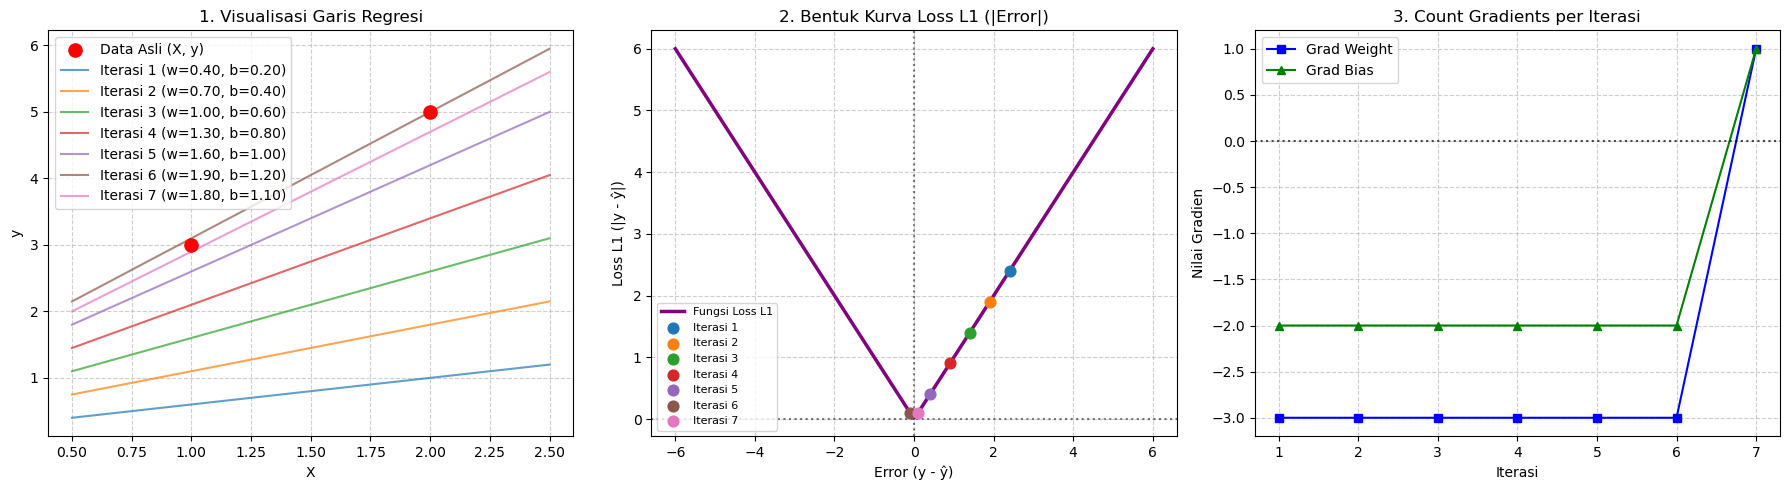

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(X, y, color='red', s=90, label='Data Asli (X, y)', zorder=5)
X_line = np.linspace(0.5, 2.5, 90)

# PLOT 1: Model RegressionLinear

for idx, row in df_history.iterrows():
    w = row['Weight']
    b = row['Bias']
    y_line = w * X_line + b
    iter_num = int(row['Iterasi'])
    axes[0].plot(X_line, y_line, label=f'Iterasi {iter_num} (w={w:.2f}, b={b:.2f})', alpha=0.7)

axes[0].set_title('1. Visualisasi Garis Regresi')
axes[0].set_xlabel('X')
axes[0].set_ylabel('y')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# PLOT 2: Loss Function (Penurunan Empirical Risk)

error_range = np.linspace(-6, 6, 300)
if model.loss_method == 'L1':
    loss_curve = np.abs(error_range)
    title_loss = "2. Bentuk Kurva Loss L1 (|Error|)"
    ylabel_loss = "Loss L1 (|y - ŷ|)"
else: 
    loss_curve = error_range ** 2
    title_loss = "2. Bentuk Kurva Loss L2 (Error²)"
    ylabel_loss = "Loss L2 ((y - ŷ)²)"

axes[1].plot(error_range, loss_curve, color='purple', linewidth=2.5, label=f'Fungsi Loss {model.loss_method}')
for idx, row in df_history.iterrows():
    w = row['Weight']
    b = row['Bias']
    error_sample = y[0] - (w * X[0] + b)
    loss_sample = np.abs(error_sample) if model.loss_method == 'L1' else error_sample**2
    iter_num = int(row['Iterasi'])
    axes[1].scatter(error_sample, loss_sample, s=60, zorder=5, label=f'Iterasi {iter_num}')
axes[1].axvline(0, color='black', linestyle=':', alpha=0.5)
axes[1].axhline(0, color='black', linestyle=':', alpha=0.5)
axes[1].set_title(title_loss)
axes[1].set_xlabel('Error (y - ŷ)')
axes[1].set_ylabel(ylabel_loss)
axes[1].legend(fontsize=8)
axes[1].grid(True, linestyle='--', alpha=0.6)

# PLOT 3: Count Gradients

axes[2].plot(df_history['Iterasi'], df_history['Grad_Weight'], marker='s', label='Grad Weight', color='blue')
axes[2].plot(df_history['Iterasi'], df_history['Grad_Bias'], marker='^', label='Grad Bias', color='green')
axes[2].axhline(0, color='black', linestyle=':', alpha=0.7)
axes[2].set_title('3. Count Gradients per Iterasi')
axes[2].set_xlabel('Iterasi')
axes[2].set_ylabel('Nilai Gradien')
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()